# Informe N1 Kiwi Chimbarongo - Graficos y outputs

Notebook simplificado para reconstruir los graficos y tablas principales del informe usando los datos de la carpeta `dataset/Datos Kiwis` y el archivo `dataset/panel_integrado.csv`.

La idea es que el codigo sea facil de seguir: primero se cargan los archivos, despues se hacen tablas resumen y finalmente se generan los graficos.

## 1. Cargar librerias y definir rutas

Todas las rutas usadas quedan visibles en la tabla de esta seccion.

In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Carpeta donde esta guardado este notebook.
carpeta_proyecto = Path.cwd()
carpeta_datos = carpeta_proyecto / 'dataset' / 'Datos Kiwis'

archivos = {
    'Panel integrado': carpeta_proyecto / 'dataset' / 'panel_integrado.csv',
    'Productivos original': carpeta_datos / 'COMPARATIVO PRODUCTIVOS.xlsx',
    'Canopia satelital': carpeta_datos / 'CONSOLIDADO_curvas_temporada_planet.xlsx',
    'Clima diario': carpeta_datos / 'datos_climaticos.xlsx',
    'ETo y ETc proxy': carpeta_datos / 'datos_eto.xlsx',
    'Costos Gantt': carpeta_datos / 'Kiwis 2026 Gantt planificacion.xlsx',
    'Fitosanitario': carpeta_datos / 'Fitosanitario_Kiwis_2025_26_V2 (1).xlsx',
    'Umbrales BBCH': carpeta_datos / 'Tabla_umbral_BBCH_frio_GDD_kiwi_prompt.xlsx',
}

tabla_rutas = pd.DataFrame({
    'archivo': archivos.keys(),
    'ruta_usada': [str(ruta.resolve()) for ruta in archivos.values()],
    'existe': [ruta.exists() for ruta in archivos.values()],
})
display(tabla_rutas)

if not tabla_rutas['existe'].all():
    raise FileNotFoundError('Falta uno o mas archivos. Revisar la tabla de rutas.')

,archivo,ruta_usada,existe
0,Panel integrado,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
1,Productivos original,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
2,Canopia satelital,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
3,Clima diario,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
4,ETo y ETc proxy,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
5,Costos Gantt,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
6,Fitosanitario,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True
7,Umbrales BBCH,C:\Users\jason\OneDrive\Desktop\DiplomadoDataS...,True


## 2. Leer los datos

El archivo climatico viene con encabezados institucionales antes de la tabla. Por eso se lee primero sin encabezado y luego se toman las columnas utiles por posicion.

In [7]:
# Panel ya consolidado a nivel cuartel-temporada.
panel = pd.read_csv(archivos['Panel integrado'])
panel['anio'] = panel['anio'].astype(int)

# Serie diaria de canopia satelital.
canopia = pd.read_excel(archivos['Canopia satelital'], sheet_name='Datos_diarios')
canopia['fecha'] = pd.to_datetime(canopia['fecha'])

# Datos de evapotranspiracion calculados previamente.
eto_diario = pd.read_excel(archivos['ETo y ETc proxy'], sheet_name='Calculos_diarios')
eto_diario['fecha'] = pd.to_datetime(eto_diario['fecha'])
eto_temporada = pd.read_excel(archivos['ETo y ETc proxy'], sheet_name='Resumen_temporada')

# Costos de la carta Gantt.
costos = pd.read_excel(archivos['Costos Gantt'], sheet_name='kiwis', header=1)

# Lectura simple del clima INIA.
clima_crudo = pd.read_excel(archivos['Clima diario'], sheet_name='datos', header=None)
fila_encabezado = clima_crudo.index[clima_crudo.iloc[:, 0].astype(str).str.contains('Tiempo', na=False)][0]
clima = clima_crudo.iloc[fila_encabezado + 1:, [0, 1, 2, 3, 4, 5, 6, 13]].copy()
clima.columns = ['fecha', 'Tmin_C', 'Tmax_C', 'RHmin_pct', 'RHmax_pct', 'precip_mm', 'Rs_MJ_m2', 'wind_kmh']
clima['fecha'] = pd.to_datetime(clima['fecha'], dayfirst=True, errors='coerce')
for columna in clima.columns[1:]:
    clima[columna] = pd.to_numeric(clima[columna], errors='coerce')
clima = clima.dropna(subset=['fecha']).sort_values('fecha')

# Temporada agricola: mayo a abril.
anio_inicio = np.where(clima['fecha'].dt.month >= 5, clima['fecha'].dt.year, clima['fecha'].dt.year - 1)
clima['temporada'] = anio_inicio.astype(str) + '-' + (anio_inicio + 1).astype(str)

print('Panel integrado:', panel.shape)
print('Canopia satelital:', canopia.shape)
print('Clima diario:', clima.shape)
print('ETo/ETc diario:', eto_diario.shape)

Panel integrado: (112, 22)
Canopia satelital: (29073, 31)
Clima diario: (1667, 9)
ETo/ETc diario: (1667, 39)


## 3. Estadisticas descriptivas

Tabla equivalente a las estadisticas descriptivas del informe.

In [8]:
variables = ['ton_ha', 'cnp_media', 'cnp_auc', 'horas_frio', 'gdd_b7', 'gdd_b10', 'precip_mm']
filas = []

for variable in variables:
    datos = panel[variable].dropna()
    filas.append({
        'Variable': variable,
        'N': len(datos),
        'Media': datos.mean(),
        'Mediana': datos.median(),
        'Moda': datos.mode().iloc[0],
        'Desv': datos.std(),
        'Min': datos.min(),
        'Max': datos.max(),
        'IQR': datos.quantile(0.75) - datos.quantile(0.25),
        'Asim': datos.skew(),
    })

descriptivos = pd.DataFrame(filas).round(3)
display(descriptivos)

,Variable,N,Media,Mediana,Moda,Desv,Min,Max,IQR,Asim
0,ton_ha,112,34.448,33.817,36.801,10.138,13.007,67.722,12.400,0.407
1,cnp_media,77,0.544,0.543,0.484,0.023,0.484,0.593,0.030,-0.261
2,cnp_auc,77,198.719,198.355,176.754,8.299,176.754,216.627,11.345,-0.274
3,horas_frio,56,1095.250,1143.500,843.000,170.634,843.000,1251.000,258.750,-0.472
4,gdd_b7,70,2060.200,2284.000,1154.000,459.481,1154.000,2338.000,143.000,-1.483
5,gdd_b10,70,1424.000,1575.000,800.000,319.242,800.000,1637.000,148.000,-1.420
6,precip_mm,70,456.680,502.200,52.600,252.223,52.600,772.300,308.700,-0.408


## 4. Figura 1 - Distribucion del rendimiento por hectarea

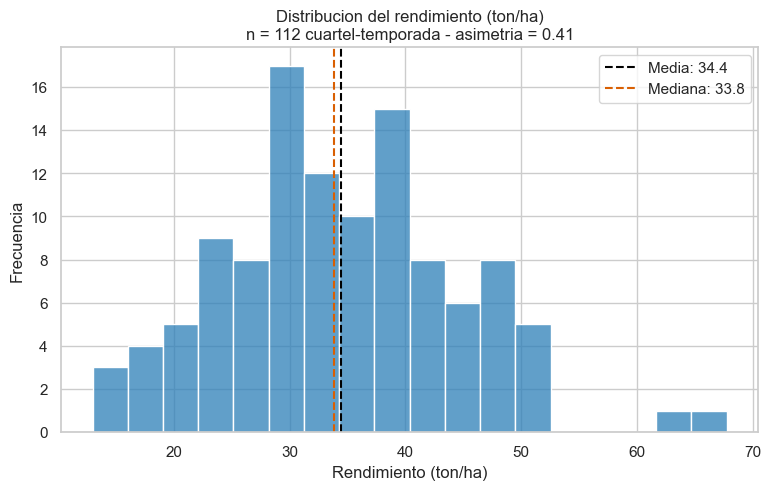

cuartel              10
anio               2026
has                3.25
kg_cuartel     220096.0
ton_ha        67.721846
Name: 15, dtype: object

In [9]:
media = panel['ton_ha'].mean()
mediana = panel['ton_ha'].median()
asimetria = panel['ton_ha'].skew()

plt.figure(figsize=(9, 5))
sns.histplot(panel['ton_ha'], bins=18, color='#2c7fb8')
plt.axvline(media, color='black', linestyle='--', label=f'Media: {media:.1f}')
plt.axvline(mediana, color='#d95f02', linestyle='--', label=f'Mediana: {mediana:.1f}')
plt.title(f'Distribucion del rendimiento (ton/ha)\nn = {len(panel)} cuartel-temporada - asimetria = {asimetria:.2f}')
plt.xlabel('Rendimiento (ton/ha)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

# Registro con mayor rendimiento por hectarea.
display(panel.loc[panel['ton_ha'].idxmax(), ['cuartel', 'anio', 'has', 'kg_cuartel', 'ton_ha']])

## 5. Figura 2 - Rendimiento por temporada de cosecha

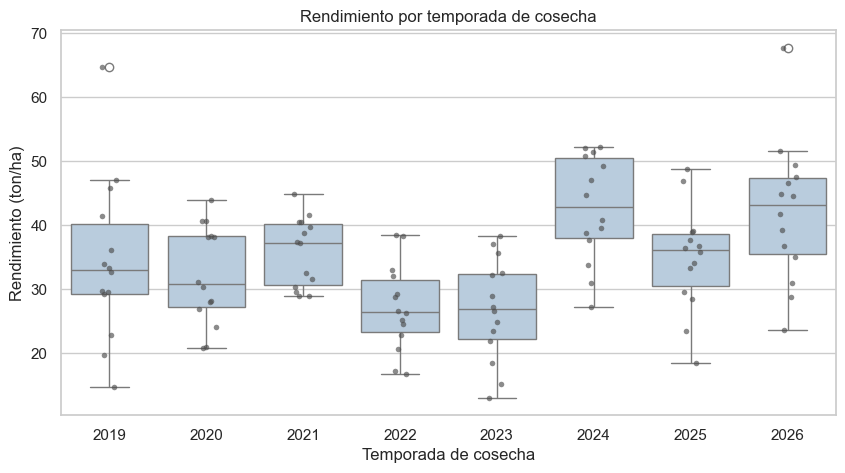

,count,mean,median,std,min,max
anio,,,,,,
2019,14,34.31,32.97,12.64,14.69,64.67
2020,14,32.13,30.75,7.75,20.75,43.93
2021,14,35.86,37.25,5.40,28.84,44.87
2022,14,27.12,26.45,6.78,16.74,38.50
2023,14,26.77,26.91,7.92,13.01,38.26
2024,14,42.56,42.79,8.30,27.20,52.15
2025,14,34.82,36.06,8.12,18.46,48.72
2026,14,42.02,43.13,11.09,23.54,67.72


In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=panel, x='anio', y='ton_ha', color='#b3cde3')
sns.stripplot(data=panel, x='anio', y='ton_ha', color='#4d4d4d', size=4, alpha=0.65)
plt.title('Rendimiento por temporada de cosecha')
plt.xlabel('Temporada de cosecha')
plt.ylabel('Rendimiento (ton/ha)')
plt.show()

resumen_anual = panel.groupby('anio')['ton_ha'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(resumen_anual)

## 6. Calidad de datos

In [11]:
calidad = pd.DataFrame([
    ['Serie climatica diaria', clima.isna().sum().sum(), len(clima), 'Sin nulos relevantes ni dias faltantes esperados.'],
    ['Senal de canopia diaria suavizada', canopia['cb_invertido_suavizado'].isna().sum(), len(canopia), 'Se usa serie suavizada a 7 dias.'],
    ['cnp_media en panel', panel['cnp_media'].isna().sum(), len(panel), 'No se imputa; cuarteles sin cobertura satelital.'],
    ['horas_frio en panel', panel['horas_frio'].isna().sum(), len(panel), 'Solo temporadas con invierno completo registrado.'],
    ['Registros productivos', panel[['ton_ha', 'kg_cuartel', 'bins', 'has']].isna().sum().sum(), len(panel), 'Panel productivo completo.'],
], columns=['Conjunto / variable', 'Faltantes', 'Registros', 'Tratamiento'])

calidad['% faltantes'] = (calidad['Faltantes'] / calidad['Registros'] * 100).round(2)
display(calidad[['Conjunto / variable', 'Faltantes', '% faltantes', 'Tratamiento']])

fechas_esperadas = pd.date_range(clima['fecha'].min(), clima['fecha'].max())
dias_faltantes = fechas_esperadas.difference(clima['fecha'])
print('Duplicados en panel:', panel.duplicated(subset=['cuartel', 'anio']).sum())
print('Dias climaticos faltantes:', len(dias_faltantes))

,Conjunto / variable,Faltantes,% faltantes,Tratamiento
0,Serie climatica diaria,0,0.00,Sin nulos relevantes ni dias faltantes esperados.
1,Senal de canopia diaria suavizada,82,0.28,Se usa serie suavizada a 7 dias.
2,cnp_media en panel,35,31.25,No se imputa; cuarteles sin cobertura satelital.
3,horas_frio en panel,56,50.00,Solo temporadas con invierno completo registrado.
4,Registros productivos,0,0.00,Panel productivo completo.


Duplicados en panel: 0
Dias climaticos faltantes: 0


## 7. Figura 3 - Curva de canopia por temporada

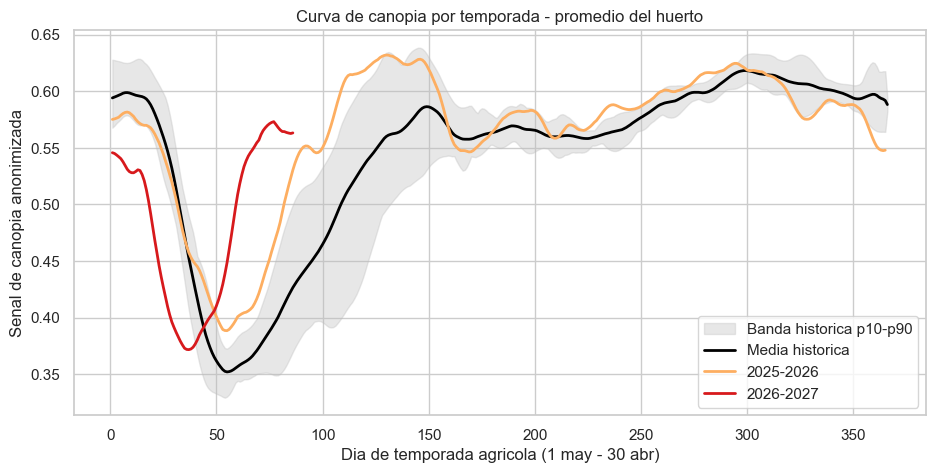

In [12]:
curvas = canopia.groupby(['temporada', 'dia_temporada'])['cb_invertido_suavizado'].mean().reset_index()
curvas = curvas.rename(columns={'cb_invertido_suavizado': 'canopia_media'})

historico = curvas[curvas['temporada'].between('2019-2020', '2025-2026')]
banda = historico.groupby('dia_temporada')['canopia_media'].agg(
    media='mean',
    p10=lambda x: x.quantile(0.10),
    p90=lambda x: x.quantile(0.90),
).reset_index()

plt.figure(figsize=(11, 5))
plt.fill_between(banda['dia_temporada'], banda['p10'], banda['p90'], color='#bdbdbd', alpha=0.35, label='Banda historica p10-p90')
plt.plot(banda['dia_temporada'], banda['media'], color='black', linewidth=2, label='Media historica')

for temporada, color in [('2025-2026', '#fdae61'), ('2026-2027', '#d7191c')]:
    datos = curvas[curvas['temporada'] == temporada]
    plt.plot(datos['dia_temporada'], datos['canopia_media'], color=color, linewidth=2, label=temporada)

plt.title('Curva de canopia por temporada - promedio del huerto')
plt.xlabel('Dia de temporada agricola (1 may - 30 abr)')
plt.ylabel('Senal de canopia anonimizada')
plt.legend()
plt.show()

## 8. Figura 4 - Variables ambientales por temporada

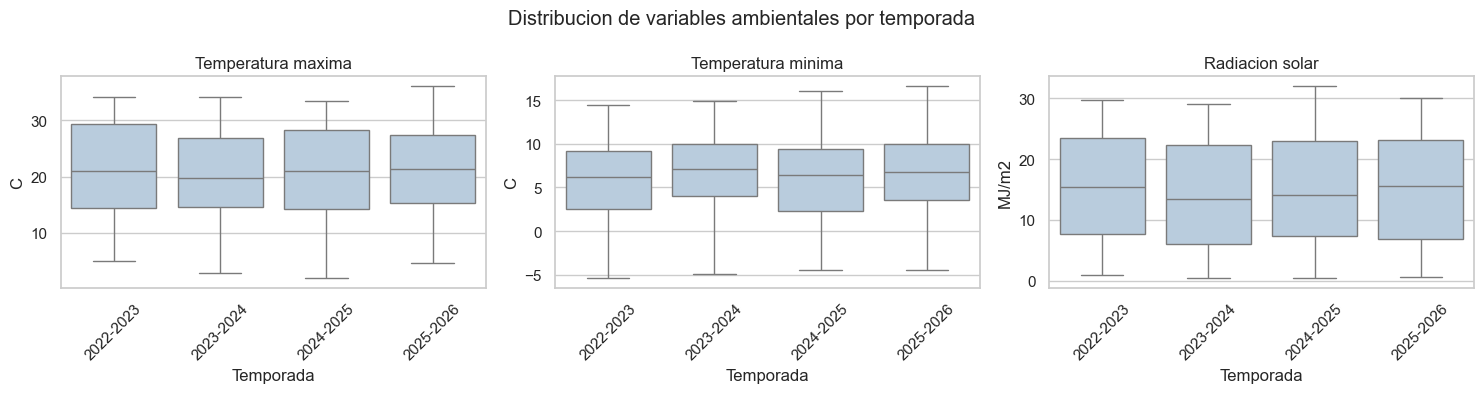

In [13]:
temporadas_clima = ['2022-2023', '2023-2024', '2024-2025', '2025-2026']
clima_grafico = clima[clima['temporada'].isin(temporadas_clima)]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
graficos = [
    ('Tmax_C', 'Temperatura maxima', 'C'),
    ('Tmin_C', 'Temperatura minima', 'C'),
    ('Rs_MJ_m2', 'Radiacion solar', 'MJ/m2'),
]

for eje, (columna, titulo, unidad) in zip(ejes, graficos):
    sns.boxplot(data=clima_grafico, x='temporada', y=columna, color='#b3cde3', ax=eje)
    eje.set_title(titulo)
    eje.set_xlabel('Temporada')
    eje.set_ylabel(unidad)
    eje.tick_params(axis='x', rotation=45)

plt.suptitle('Distribucion de variables ambientales por temporada')
plt.tight_layout()
plt.show()

## 9. Figura 5 - Horas de frio y grados-dia

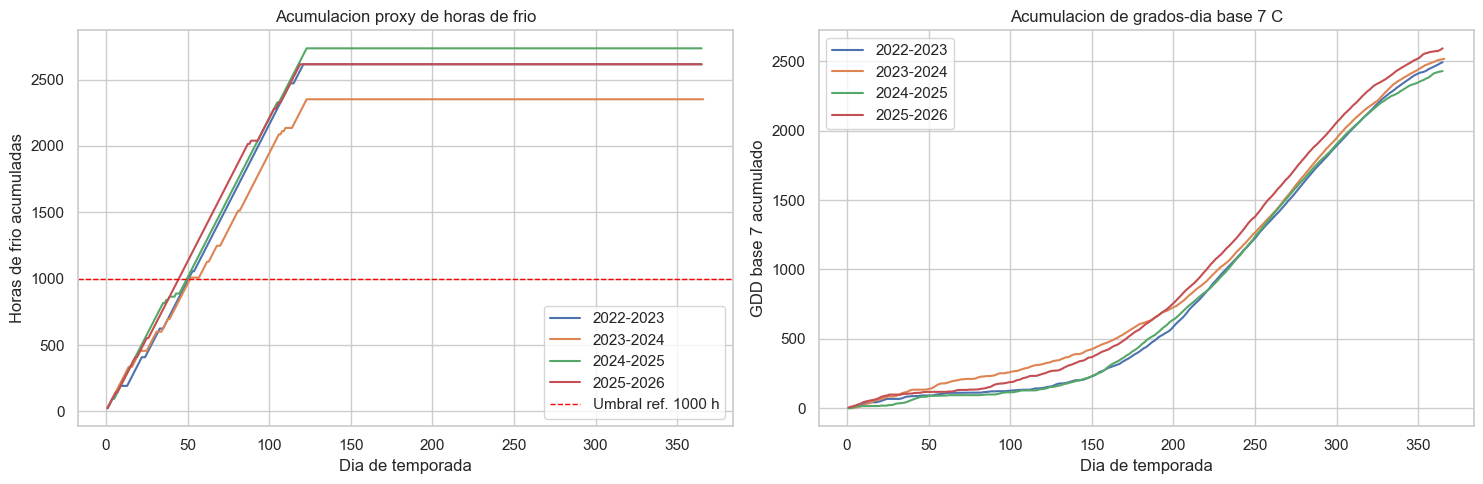

,horas_frio,gdd_b7,gdd_b10,precip_mm
temporada,,,,
2022-2023,1251.0,2338.0,1637.0,323.8
2023-2024,843.0,2191.0,1480.0,772.3
2024-2025,1248.0,2284.0,1575.0,632.5
2025-2026,1039.0,2334.0,1628.0,502.2


In [14]:
clima_acum = clima.copy()
fecha_inicio_temporada = pd.to_datetime(clima_acum['temporada'].str[:4] + '-05-01')
clima_acum['dia_temporada'] = (clima_acum['fecha'] - fecha_inicio_temporada).dt.days + 1
clima_acum['Tmean_C'] = (clima_acum['Tmin_C'] + clima_acum['Tmax_C']) / 2

# Calculos simples para visualizar acumulaciones.
clima_acum['frio_dia_proxy'] = np.where(clima_acum['Tmin_C'] <= 7.2, 24, 0)
clima_acum['gdd_b7_dia'] = np.maximum(clima_acum['Tmean_C'] - 7, 0)
clima_acum = clima_acum[clima_acum['temporada'].isin(temporadas_clima)]

es_invierno = clima_acum['fecha'].dt.month.isin([5, 6, 7, 8])
clima_acum['frio_dia_proxy'] = np.where(es_invierno, clima_acum['frio_dia_proxy'], 0)
clima_acum['frio_acum'] = clima_acum.groupby('temporada')['frio_dia_proxy'].cumsum()
clima_acum['gdd_b7_acum'] = clima_acum.groupby('temporada')['gdd_b7_dia'].cumsum()

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for temporada in temporadas_clima:
    datos = clima_acum[clima_acum['temporada'] == temporada]
    ejes[0].plot(datos['dia_temporada'], datos['frio_acum'], label=temporada)
    ejes[1].plot(datos['dia_temporada'], datos['gdd_b7_acum'], label=temporada)

ejes[0].axhline(1000, color='red', linestyle='--', linewidth=1, label='Umbral ref. 1000 h')
ejes[0].set_title('Acumulacion proxy de horas de frio')
ejes[0].set_xlabel('Dia de temporada')
ejes[0].set_ylabel('Horas de frio acumuladas')
ejes[0].legend()

ejes[1].set_title('Acumulacion de grados-dia base 7 C')
ejes[1].set_xlabel('Dia de temporada')
ejes[1].set_ylabel('GDD base 7 acumulado')
ejes[1].legend()

plt.tight_layout()
plt.show()

display(panel.dropna(subset=['horas_frio']).groupby('temporada')[['horas_frio', 'gdd_b7', 'gdd_b10', 'precip_mm']].mean().round(1))

## 10. Figura 6 - ETo y ETc proxy

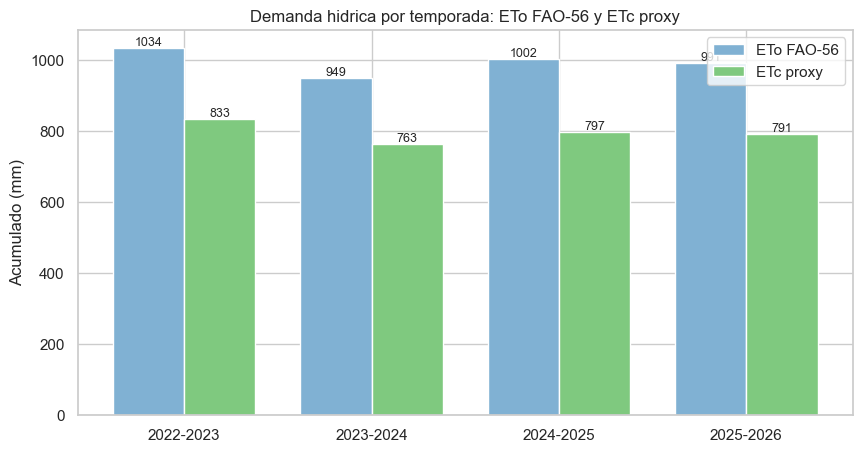

,temporada,ETo_sum_mm,ETc_proxy_sum_mm,precip_sum_mm,deficit_proxy_sum_mm,Kc_proxy_mean
1,2022-2023,1033.7,832.7,323.8,508.9,0.7
2,2023-2024,948.7,763.0,772.3,-9.3,0.7
3,2024-2025,1002.1,797.2,632.5,164.7,0.7
4,2025-2026,990.9,791.3,502.2,289.1,0.7


In [15]:
eto_grafico = eto_temporada[eto_temporada['temporada'].isin(temporadas_clima)].copy()
x = np.arange(len(eto_grafico))
ancho = 0.38

fig, eje = plt.subplots(figsize=(10, 5))
eje.bar(x - ancho/2, eto_grafico['ETo_sum_mm'], ancho, label='ETo FAO-56', color='#80b1d3')
eje.bar(x + ancho/2, eto_grafico['ETc_proxy_sum_mm'], ancho, label='ETc proxy', color='#7fc97f')
eje.set_xticks(x)
eje.set_xticklabels(eto_grafico['temporada'])
eje.set_title('Demanda hidrica por temporada: ETo FAO-56 y ETc proxy')
eje.set_ylabel('Acumulado (mm)')
eje.legend()

for barras in eje.containers:
    eje.bar_label(barras, fmt='%.0f', fontsize=9)

plt.show()
display(eto_grafico[['temporada', 'ETo_sum_mm', 'ETc_proxy_sum_mm', 'precip_sum_mm', 'deficit_proxy_sum_mm', 'Kc_proxy_mean']].round(1))

## 11. Figuras 7 y 8 - Correlaciones y relacion canopia-rendimiento

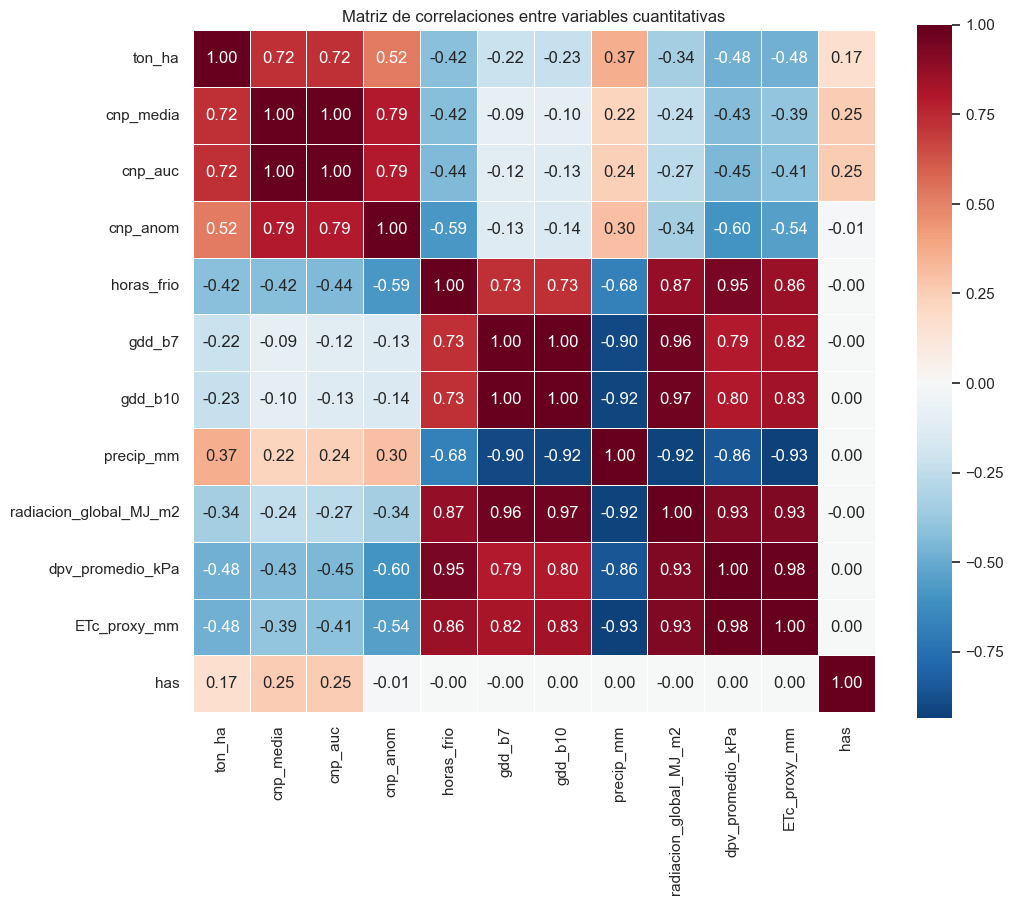

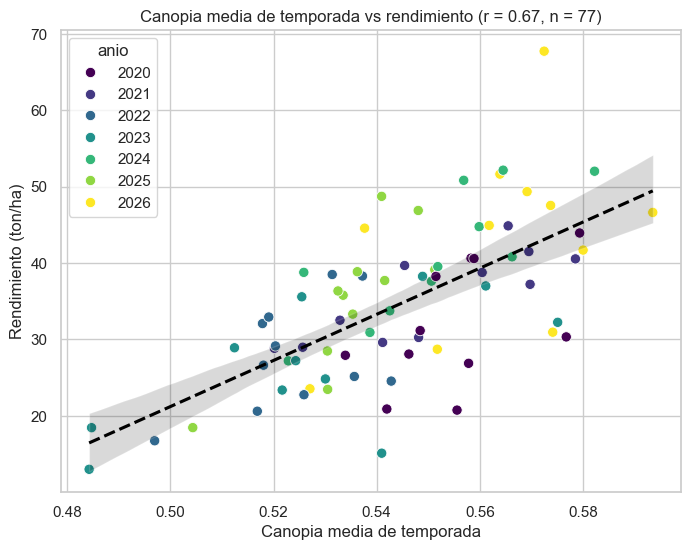

,corr_con_ton_ha
ton_ha,1.000
cnp_auc,0.724
cnp_media,0.722
cnp_anom,0.518
precip_mm,0.365
has,0.166
gdd_b7,-0.217
gdd_b10,-0.230
radiacion_global_MJ_m2,-0.339
horas_frio,-0.418


Variables agregadas a la matriz:
- radiacion_global_MJ_m2: suma por temporada de Rs_MJ_m2 desde datos_eto.xlsx
- dpv_promedio_kPa: promedio por temporada de es_kPa - ea_kPa
- ETc_proxy_mm: suma por temporada de ETc_proxy_mm_dia


In [16]:
# Variables ambientales adicionales desde datos_eto.xlsx.
# Se agregan por temporada para poder cruzarlas con el panel cuartel-temporada.
eto_corr = eto_diario.copy()
eto_corr['DPV_kPa'] = eto_corr['es_kPa'] - eto_corr['ea_kPa']

eto_temporada_corr = eto_corr.groupby('temporada').agg(
    radiacion_global_MJ_m2=('Rs_MJ_m2', 'sum'),
    dpv_promedio_kPa=('DPV_kPa', 'mean'),
    ETc_proxy_mm=('ETc_proxy_mm_dia', 'sum'),
).reset_index()

panel_corr = panel.merge(eto_temporada_corr, on='temporada', how='left')

variables_corr = [
    'ton_ha',
    'cnp_media',
    'cnp_auc',
    'cnp_anom',
    'horas_frio',
    'gdd_b7',
    'gdd_b10',
    'precip_mm',
    'radiacion_global_MJ_m2',
    'dpv_promedio_kPa',
    'ETc_proxy_mm',
    'has',
]

correlaciones = panel_corr[variables_corr].dropna().corr()

plt.figure(figsize=(11, 9))
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, linewidths=.5)
plt.title('Matriz de correlaciones entre variables cuantitativas')
plt.show()

panel_canopia = panel.dropna(subset=['cnp_media', 'ton_ha']).copy()
r_canopia = panel_canopia['cnp_media'].corr(panel_canopia['ton_ha'])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=panel_canopia, x='cnp_media', y='ton_ha', hue='anio', palette='viridis', s=55)
sns.regplot(data=panel_canopia, x='cnp_media', y='ton_ha', scatter=False, color='black', line_kws={'linestyle': '--'})
plt.title(f'Canopia media de temporada vs rendimiento (r = {r_canopia:.2f}, n = {len(panel_canopia)})')
plt.xlabel('Canopia media de temporada')
plt.ylabel('Rendimiento (ton/ha)')
plt.show()

display(correlaciones['ton_ha'].sort_values(ascending=False).round(3).to_frame('corr_con_ton_ha'))

print('Variables agregadas a la matriz:')
print('- radiacion_global_MJ_m2: suma por temporada de Rs_MJ_m2 desde datos_eto.xlsx')
print('- dpv_promedio_kPa: promedio por temporada de es_kPa - ea_kPa')
print('- ETc_proxy_mm: suma por temporada de ETc_proxy_mm_dia')

## 12. Figura 9 - Punto de equilibrio preliminar

Se usan los mismos supuestos del informe: precio de referencia de $450/kg, costo de cosecha de $5.000 por bin y 441 kg por bin. La carta Gantt disponible no incluye todos los costos del negocio, por lo tanto este punto de equilibrio es un piso.

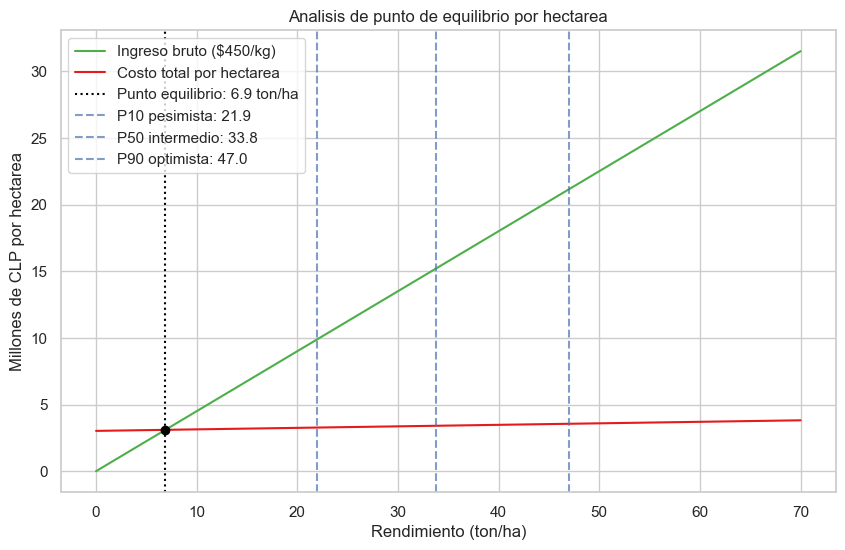

,indicador,valor
0,Superficie panel (ha),3.415000e+01
1,Costo fijo usado informe,1.032000e+08
2,Costo fijo por ha,3.021962e+06
3,Costo variable cosecha $/kg,1.133787e+01
4,Precio referencia $/kg,4.500000e+02
5,Punto equilibrio ton/ha,6.889042e+00


,ton_ha
P10 pesimista,21.91
P50 intermedio,33.82
P90 optimista,47.03


In [17]:
precio_kg = 450
costo_bin = 5000
kg_por_bin = 441
costo_variable_kg = costo_bin / kg_por_bin

superficie_total_ha = panel[['cuartel', 'has']].drop_duplicates()['has'].sum()
costo_fijo_total = 103_200_000
costo_fijo_ha = costo_fijo_total / superficie_total_ha
punto_equilibrio_ton_ha = costo_fijo_ha / (precio_kg - costo_variable_kg) / 1000

percentiles = panel['ton_ha'].quantile([0.10, 0.50, 0.90])
percentiles.index = ['P10 pesimista', 'P50 intermedio', 'P90 optimista']

rendimiento = np.linspace(0, 70, 200)
ingreso_millones = rendimiento * 1000 * precio_kg / 1_000_000
costo_millones = (costo_fijo_ha + rendimiento * 1000 * costo_variable_kg) / 1_000_000

plt.figure(figsize=(10, 6))
plt.plot(rendimiento, ingreso_millones, color='#4daf4a', label=f'Ingreso bruto (${precio_kg}/kg)')
plt.plot(rendimiento, costo_millones, color='#e41a1c', label='Costo total por hectarea')
plt.axvline(punto_equilibrio_ton_ha, color='black', linestyle=':', label=f'Punto equilibrio: {punto_equilibrio_ton_ha:.1f} ton/ha')
plt.scatter([punto_equilibrio_ton_ha], [punto_equilibrio_ton_ha * 1000 * precio_kg / 1_000_000], color='black', zorder=5)

for nombre, valor in percentiles.items():
    plt.axvline(valor, linestyle='--', alpha=0.7, label=f'{nombre}: {valor:.1f}')

plt.title('Analisis de punto de equilibrio por hectarea')
plt.xlabel('Rendimiento (ton/ha)')
plt.ylabel('Millones de CLP por hectarea')
plt.legend(loc='upper left')
plt.show()

resumen_economico = pd.DataFrame({
    'indicador': [
        'Superficie panel (ha)',
        'Costo fijo usado informe',
        'Costo fijo por ha',
        'Costo variable cosecha $/kg',
        'Precio referencia $/kg',
        'Punto equilibrio ton/ha',
    ],
    'valor': [
        superficie_total_ha,
        costo_fijo_total,
        costo_fijo_ha,
        costo_variable_kg,
        precio_kg,
        punto_equilibrio_ton_ha,
    ],
})

display(resumen_economico)
display(percentiles.round(2).to_frame('ton_ha'))

## 13. Sintesis del EDA

In [18]:
print('Hallazgos principales')
print(f'- Rendimiento medio: {panel.ton_ha.mean():.2f} ton/ha; mediana: {panel.ton_ha.median():.2f}; rango: {panel.ton_ha.min():.2f} a {panel.ton_ha.max():.2f}.')
print(f'- Temporada de menor media: {resumen_anual["mean"].idxmin()} ({resumen_anual["mean"].min():.1f} ton/ha).')
print(f'- Temporada de mayor media: {resumen_anual["mean"].idxmax()} ({resumen_anual["mean"].max():.1f} ton/ha).')
print(f'- Correlacion canopia media vs rendimiento: {r_canopia:.2f} con {len(panel_canopia)} observaciones con canopia.')
print(f'- Punto de equilibrio preliminar: {punto_equilibrio_ton_ha:.1f} ton/ha con precio ${precio_kg}/kg.')
print('- El costo economico es parcial: falta incorporar insumos, fertilizacion, riego, energia y administracion.')

Hallazgos principales
- Rendimiento medio: 34.45 ton/ha; mediana: 33.82; rango: 13.01 a 67.72.
- Temporada de menor media: 2023 (26.8 ton/ha).
- Temporada de mayor media: 2024 (42.6 ton/ha).
- Correlacion canopia media vs rendimiento: 0.67 con 77 observaciones con canopia.
- Punto de equilibrio preliminar: 6.9 ton/ha con precio $450/kg.
- El costo economico es parcial: falta incorporar insumos, fertilizacion, riego, energia y administracion.
